# Unit 3 — Image Restoration and Segmentation (Task 1)

**What this notebook does**

| Part | Steps |
|---|---|
| A. Image restoration | add Gaussian noise and salt-and-pepper noise → clean them with a Median filter and a Gaussian filter → measure quality with PSNR and SSIM |
| B. Morphology and segmentation | thresholding → erosion, dilation, opening, closing → Canny edge detection → watershed segmentation |

**Input:** `data/photo1.jpeg` (your own photo).
Optional: `data/objects.jpg` (a photo of coins or other touching objects on a plain background, used for watershed).
If `objects.jpeg` is missing, watershed uses `photo1.jpeg`.

**Output:** every result image is saved in `outputs/unit3/`.

Run the cells from top to bottom (*Kernel → Restart & Run All*).

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

OUT = "outputs/unit3"          # all results of this notebook go here
os.makedirs(OUT, exist_ok=True)


def load_image(path, width=800):
    # Read a photo and shrink it to 800 pixels wide (keeps the shape the same)
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read {path}. Put your photo in the data folder.")
    h, w = img.shape[:2]
    if w > width:
        img = cv2.resize(img, (width, int(h * width / w)))
    return img


def show(images, titles, cols=3):
    # Show many images in a grid. OpenCV stores colour as BGR, matplotlib wants RGB.
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(5 * cols, 4 * rows))
    for i in range(len(images)):
        plt.subplot(rows, cols, i + 1)
        if images[i].ndim == 2:                       # grayscale / mask
            plt.imshow(images[i], cmap="gray")
        else:                                          # colour
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis("off")
    plt.tight_layout()
    plt.show()


def save(name, img):
    cv2.imwrite(os.path.join(OUT, name), img)

## Step 0 — Load the photo

Phone photos are very large (for example 4000 × 3000 pixels). We shrink the photo to 800 pixels wide so that every step runs fast.
We also make a **grayscale** copy (one brightness value per pixel instead of three colour values), because thresholding, edges and morphology work on one channel.

Colour image shape (height, width, channels): (1066, 800, 3)
Grayscale image shape (height, width): (1066, 800)


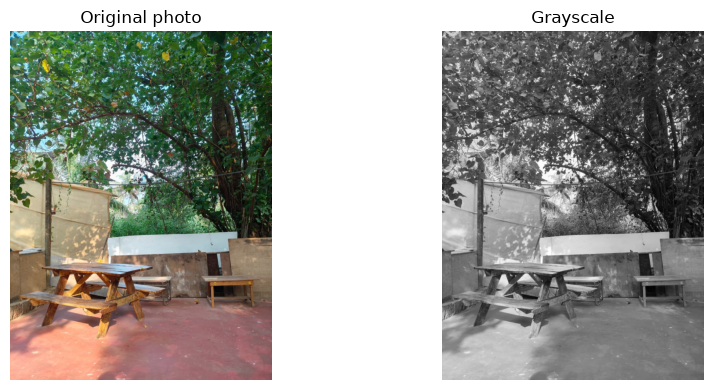

In [2]:
PHOTO_PATH = "data/photo1.jpeg"

original = load_image(PHOTO_PATH)
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

print("Colour image shape (height, width, channels):", original.shape)
print("Grayscale image shape (height, width):", gray.shape)

show([original, gray], ["Original photo", "Grayscale"], cols=2)
save("00_original.jpg", original)
save("00_gray.jpg", gray)

---
# Part A — Image Restoration

## A1. Add noise to the photo

* **Gaussian noise** – we add a small random number to *every* pixel. Most numbers are close to 0, a few are bigger (a bell-shaped curve). It looks like fine grain, like a photo taken in low light.
  `std = 25` controls how strong the noise is.
* **Salt-and-pepper noise** – we pick some random pixels and make them pure white (255 = salt) or pure black (0 = pepper). It looks like dust or dead pixels.
  Here 5% of pixels become black and 5% become white.

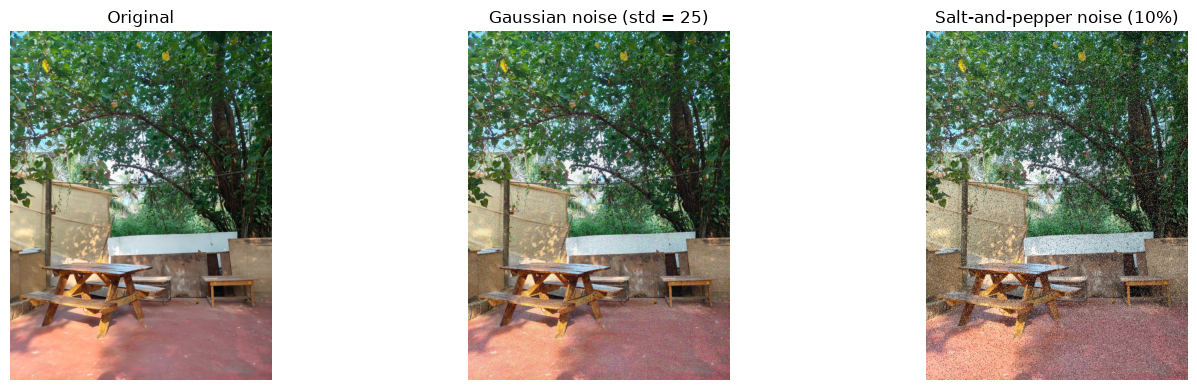

In [3]:
np.random.seed(42)    # fixed seed = the same "random" noise every time we run

# Gaussian noise: random numbers with mean 0 and standard deviation 25
noise = np.random.normal(0, 25, original.shape)
gaussian_noisy = np.clip(original + noise, 0, 255).astype(np.uint8)   # keep values inside 0..255

# Salt-and-pepper noise
sp_noisy = original.copy()
r = np.random.rand(original.shape[0], original.shape[1])   # one random number (0..1) per pixel
sp_noisy[r < 0.05] = 0      # 5% pepper (black)
sp_noisy[r > 0.95] = 255    # 5% salt (white)

show([original, gaussian_noisy, sp_noisy],
     ["Original", "Gaussian noise (std = 25)", "Salt-and-pepper noise (10%)"])
save("01_gaussian_noisy.jpg", gaussian_noisy)
save("01_saltpepper_noisy.jpg", sp_noisy)

## A2. Restore the noisy images with filters

A filter slides a small window (here 5 × 5 pixels) over the image and replaces the centre pixel with a new value computed from its neighbours.

* **Gaussian filter** – replaces the pixel with a *weighted average* of its neighbours (closer pixels get more weight). Good at smoothing grain, but it also blurs edges.
* **Median filter** – sorts the 25 neighbour values and picks the *middle* one. A single very bright or very dark pixel can never be the middle value, so salt-and-pepper dots disappear completely.

We apply **both** filters to **both** noisy images, so we can compare all 4 combinations.

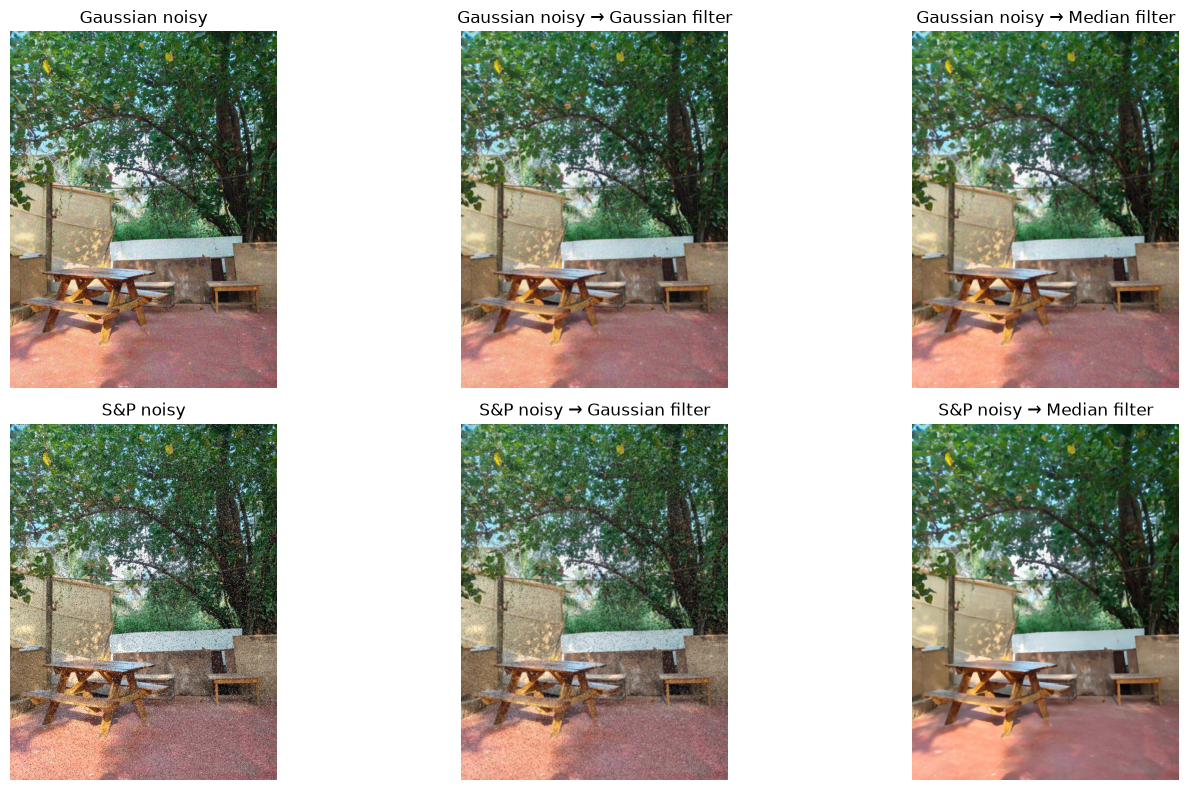

In [4]:
K = 5   # window size: 5 x 5 pixels (must be an odd number)

gauss_on_gauss  = cv2.GaussianBlur(gaussian_noisy, (K, K), 0)   # 0 = let OpenCV pick sigma from K
median_on_gauss = cv2.medianBlur(gaussian_noisy, K)
gauss_on_sp     = cv2.GaussianBlur(sp_noisy, (K, K), 0)
median_on_sp    = cv2.medianBlur(sp_noisy, K)

show([gaussian_noisy, gauss_on_gauss, median_on_gauss,
      sp_noisy, gauss_on_sp, median_on_sp],
     ["Gaussian noisy", "Gaussian noisy → Gaussian filter", "Gaussian noisy → Median filter",
      "S&P noisy", "S&P noisy → Gaussian filter", "S&P noisy → Median filter"])

save("02_gaussian_noise_gaussian_filter.jpg", gauss_on_gauss)
save("02_gaussian_noise_median_filter.jpg", median_on_gauss)
save("02_sp_noise_gaussian_filter.jpg", gauss_on_sp)
save("02_sp_noise_median_filter.jpg", median_on_sp)

## A3 & A4. Compare with the original using PSNR and SSIM

* **PSNR (Peak Signal-to-Noise Ratio)** – measures how different the pixel values are from the original, in decibels (dB).
  Higher = closer to the original. Roughly: below 20 dB is poor, 20–30 dB is okay, above 30 dB is good.
* **SSIM (Structural Similarity Index)** – measures how similar the *structure* (edges, textures, brightness, contrast) looks to a human. Range 0 to 1, where 1 = identical.

`data_range=255` tells the functions that our pixel values go from 0 to 255.
`channel_axis=2` tells SSIM that the 3rd dimension of the array is the colour channel.

The printed table is in Markdown format, so you can copy it straight into your report.

In [5]:
results = {
    "Gaussian noisy (no filter)":       gaussian_noisy,
    "Gaussian noise → Gaussian filter": gauss_on_gauss,
    "Gaussian noise → Median filter":   median_on_gauss,
    "S&P noisy (no filter)":            sp_noisy,
    "S&P noise → Gaussian filter":      gauss_on_sp,
    "S&P noise → Median filter":        median_on_sp,
}

scores = {}
for name, img in results.items():
    p = psnr(original, img, data_range=255)
    s = ssim(original, img, data_range=255, channel_axis=2)
    scores[name] = (p, s)

print("| Image | PSNR (dB) – higher is better | SSIM – higher is better |")
print("|---|---|---|")
for name, (p, s) in scores.items():
    print(f"| {name} | {p:.2f} | {s:.3f} |")

| Image | PSNR (dB) – higher is better | SSIM – higher is better |
|---|---|---|
| Gaussian noisy (no filter) | 20.46 | 0.434 |
| Gaussian noise → Gaussian filter | 25.73 | 0.734 |
| Gaussian noise → Median filter | 23.73 | 0.649 |
| S&P noisy (no filter) | 15.03 | 0.276 |
| S&P noise → Gaussian filter | 22.94 | 0.568 |
| S&P noise → Median filter | 24.37 | 0.774 |


In [6]:
# Which filter won for each type of noise? (compare PSNR)
if scores["Gaussian noise → Gaussian filter"][0] > scores["Gaussian noise → Median filter"][0]:
    print("Best for Gaussian noise: Gaussian filter")
else:
    print("Best for Gaussian noise: Median filter")

if scores["S&P noise → Gaussian filter"][0] > scores["S&P noise → Median filter"][0]:
    print("Best for salt-and-pepper noise: Gaussian filter")
else:
    print("Best for salt-and-pepper noise: Median filter")

Best for Gaussian noise: Gaussian filter
Best for salt-and-pepper noise: Median filter


**Observation (Part A)** – *check against your own numbers and edit if needed*

* For **salt-and-pepper noise**, the **median filter** is clearly the best. The Gaussian filter only spreads each white/black dot into a grey blob, while the median throws the extreme values away.
* For **Gaussian noise**, both filters help a lot and give **similar** scores – which one wins depends on the photo. The Gaussian filter is the textbook choice (averaging cancels the random + and − errors); the median filter keeps edges a little sharper, which can give it a higher SSIM.
* PSNR and SSIM both go **up** after filtering, which proves the restoration worked.

---
# Part B — Morphological Processing and Segmentation

## B5. Thresholding → binary image

Thresholding turns a grayscale image into a **binary** image (only black 0 and white 255):
if a pixel is brighter than the threshold value it becomes white, otherwise black.

* **Fixed threshold** – we choose the value ourselves (127 = the middle of 0..255).
* **Otsu's threshold** – the computer looks at the histogram (how many pixels have each brightness) and automatically chooses the value that best separates the dark group from the bright group.

We blur the image slightly first so that tiny noise does not create random dots.

Threshold chosen by Otsu: 112.0


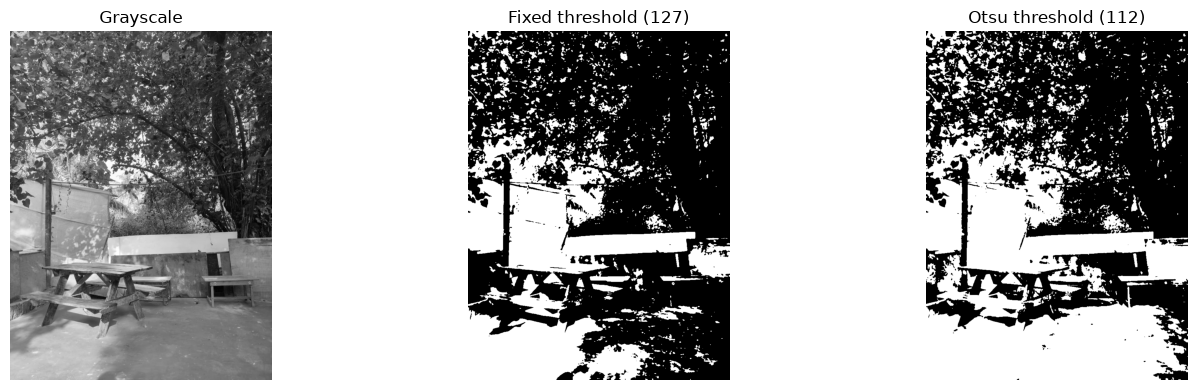

In [7]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)

_, binary_fixed = cv2.threshold(blur, 127, 255, cv2.THRESH_BINARY)
otsu_value, binary_otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Threshold chosen by Otsu:", otsu_value)

show([gray, binary_fixed, binary_otsu],
     ["Grayscale", "Fixed threshold (127)", f"Otsu threshold ({otsu_value:.0f})"])
save("03_binary_fixed.jpg", binary_fixed)
save("03_binary_otsu.jpg", binary_otsu)

## B6. Erosion, dilation, opening and closing

These operations change the **shape** of the white regions in a binary image, using a small square called a *kernel* or *structuring element* (here 5 × 5).

| Operation | What it does | Simple idea |
|---|---|---|
| **Erosion** | white regions get thinner, small white dots vanish | "eat away" the white border |
| **Dilation** | white regions get thicker, small holes fill up | "grow" the white border |
| **Opening** | erosion, then dilation | removes small white noise dots, keeps big shapes |
| **Closing** | dilation, then erosion | fills small black holes and gaps, keeps big shapes |

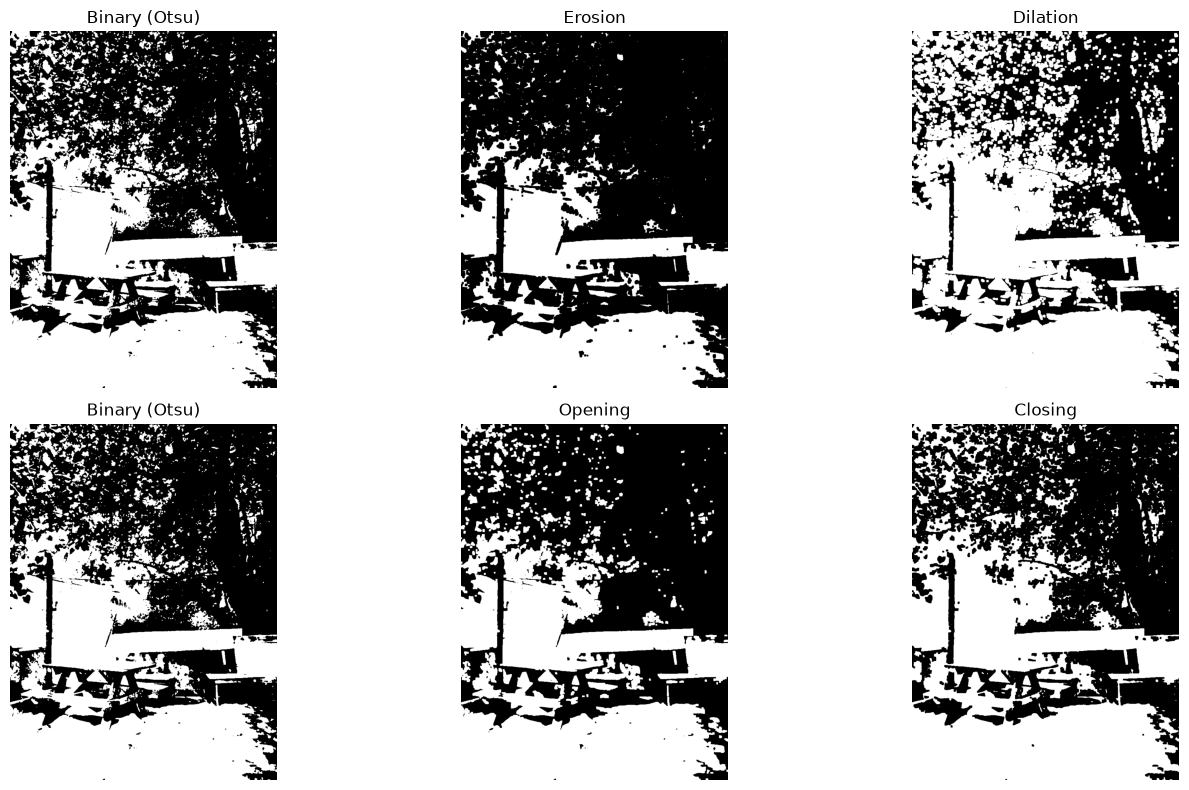

| Operation | White pixels (%) |
|---|---|
| Binary (Otsu) | 46.9 |
| Erosion | 36.5 |
| Dilation | 60.5 |
| Opening | 43.4 |
| Closing | 49.1 |


In [8]:
kernel = np.ones((5, 5), np.uint8)     # 5 x 5 square of ones
binary = binary_otsu

eroded  = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opened  = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closed  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

show([binary, eroded, dilated, binary, opened, closed],
     ["Binary (Otsu)", "Erosion", "Dilation", "Binary (Otsu)", "Opening", "Closing"])

save("04_erosion.jpg", eroded)
save("04_dilation.jpg", dilated)
save("04_opening.jpg", opened)
save("04_closing.jpg", closed)

# How much of the image is white after each operation?
print("| Operation | White pixels (%) |")
print("|---|---|")
for name, img in [("Binary (Otsu)", binary), ("Erosion", eroded), ("Dilation", dilated),
                  ("Opening", opened), ("Closing", closed)]:
    print(f"| {name} | {100 * np.count_nonzero(img) / img.size:.1f} |")

## B7. Canny edge detection

Canny finds **edges** – places where brightness changes suddenly (the outline of objects).
It takes two thresholds:

* gradient above the **high** threshold → definitely an edge
* gradient below the **low** threshold → definitely not an edge
* in between → kept only if it is connected to a strong edge

We try a few settings to compare: lower thresholds give more edges (and more noise), higher thresholds give only strong edges.
We also run Canny on the *noisy* image to show why smoothing first is important.

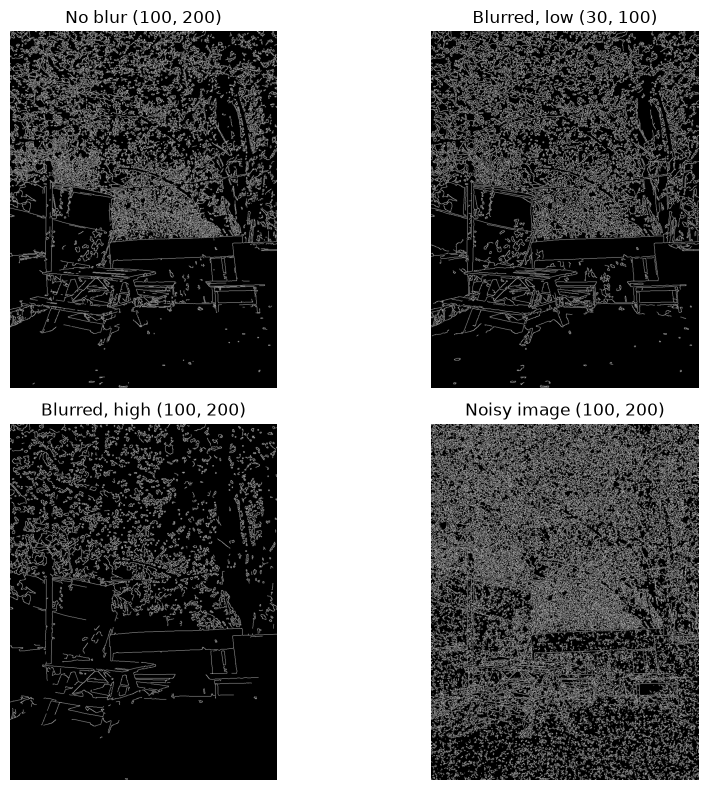

| Setting | Edge pixels (%) |
|---|---|
| No blur (100, 200) | 12.79 |
| Blurred, low (30, 100) | 13.37 |
| Blurred, high (100, 200) | 6.56 |
| Noisy image (100, 200) | 25.17 |


In [9]:
edges_no_blur = cv2.Canny(gray, 100, 200)
edges_low     = cv2.Canny(blur, 30, 100)     # blurred + low thresholds
edges_high    = cv2.Canny(blur, 100, 200)    # blurred + high thresholds
noisy_gray    = cv2.cvtColor(gaussian_noisy, cv2.COLOR_BGR2GRAY)
edges_noisy   = cv2.Canny(noisy_gray, 100, 200)

show([edges_no_blur, edges_low, edges_high, edges_noisy],
     ["No blur (100, 200)", "Blurred, low (30, 100)", "Blurred, high (100, 200)", "Noisy image (100, 200)"],
     cols=2)

save("05_canny_no_blur.jpg", edges_no_blur)
save("05_canny_low.jpg", edges_low)
save("05_canny_high.jpg", edges_high)
save("05_canny_noisy.jpg", edges_noisy)

print("| Setting | Edge pixels (%) |")
print("|---|---|")
for name, img in [("No blur (100, 200)", edges_no_blur), ("Blurred, low (30, 100)", edges_low),
                  ("Blurred, high (100, 200)", edges_high), ("Noisy image (100, 200)", edges_noisy)]:
    print(f"| {name} | {100 * np.count_nonzero(img) / img.size:.2f} |")

## B8. Watershed segmentation (separating touching objects)

Imagine the grayscale image as a **landscape**: dark = valleys, bright = hills.
If we pour water into each valley, the water from different valleys meets at "ridges". Watershed builds a wall (boundary) wherever two floods meet.

To stop it from cutting the image into hundreds of tiny pieces, we first give it **markers** – one seed point per object:

1. Make a binary mask (objects white, background black).
2. Clean small noise with *opening*.
3. **Sure background** – dilate the mask; anything still black is surely background.
4. **Sure foreground** – the *distance transform* gives each white pixel its distance to the nearest black pixel. Object centres have the biggest values, so we keep only pixels above 50% of the maximum distance. Touching objects get **separate** centres here.
5. **Unknown region** = sure background − sure foreground (the borders we are not sure about).
6. Give every sure-foreground blob its own number (marker). Unknown pixels get 0.
7. Run `cv2.watershed` – it fills the unknown pixels and marks the boundaries with −1 (drawn in red).

Best input: coins, bottle caps, sweets or fruit touching each other on a plain sheet of paper (`data/objects.jpg`).

Watershed input: data/objects.jpeg


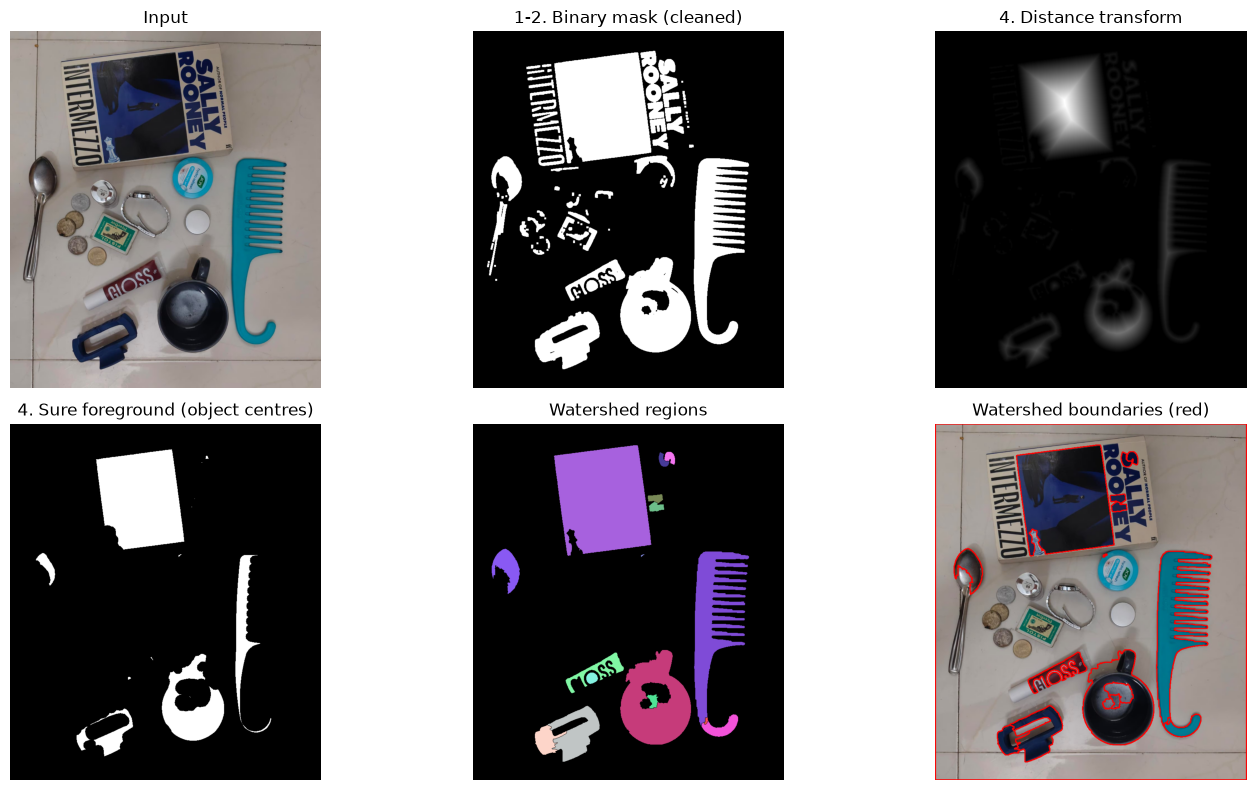

Plain mask, ignoring tiny specks (area > 500 px): 31
Objects counted from the plain binary mask: 83 (touching objects are counted as one)
Objects found by watershed:               17


In [14]:
WATERSHED_PATH = "data/objects.jpeg" if os.path.exists("data/objects.jpeg") else PHOTO_PATH
print("Watershed input:", WATERSHED_PATH)

ws_img = load_image(WATERSHED_PATH)
ws_gray = cv2.cvtColor(ws_img, cv2.COLOR_BGR2GRAY)
ws_blur = cv2.GaussianBlur(ws_gray, (5, 5), 0)
small_kernel = np.ones((3, 3), np.uint8)

# 1. Binary mask with Otsu. We want objects WHITE and background BLACK.
_, mask = cv2.threshold(ws_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
if np.mean(mask) > 127:              # more than half the image is white → background became white
    mask = cv2.bitwise_not(mask)     # so flip black and white

# 2. Remove small white noise
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, small_kernel, iterations=2)

# 3. Sure background
sure_bg = cv2.dilate(mask, small_kernel, iterations=3)

# 4. Sure foreground using the distance transform
dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
FG_RATIO = 0.1                     # try 0.3 - 0.7 if objects are not separated well
_, sure_fg = cv2.threshold(dist, FG_RATIO * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

# 5. Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# 6. Markers: background = 1, each object = 2, 3, 4 ..., unknown = 0
num_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# 7. Watershed
markers = cv2.watershed(ws_img, markers)

# Draw the result: red boundaries + a random colour for every object
result = ws_img.copy()
boundary = cv2.dilate((markers == -1).astype(np.uint8), small_kernel)   # make the 1-pixel lines thicker
result[boundary == 1] = [0, 0, 255]

np.random.seed(0)
colored = np.zeros_like(ws_img)
for label in range(2, markers.max() + 1):
    colored[markers == label] = np.random.randint(50, 255, 3)

show([ws_img, mask, dist, sure_fg, colored, result],
     ["Input", "1-2. Binary mask (cleaned)", "4. Distance transform",
      "4. Sure foreground (object centres)", "Watershed regions", "Watershed boundaries (red)"])

save("06_watershed_mask.jpg", mask)
save("06_watershed_distance.jpg", cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8))
save("06_watershed_sure_fg.jpg", sure_fg)
save("06_watershed_regions.jpg", colored)
save("06_watershed_result.jpg", result)

# Count only blobs bigger than 500 pixels, so tiny specks are not counted as objects
n, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
big_blobs = sum(1 for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] > 500)
print("Plain mask, ignoring tiny specks (area > 500 px):", big_blobs)

# Compare: counting blobs in the plain mask vs. after watershed
num_simple, _ = cv2.connectedComponents(mask)
print("Objects counted from the plain binary mask:", num_simple - 1, "(touching objects are counted as one)")
print("Objects found by watershed:              ", num_labels - 1)

---
## Summary — which technique worked best?

*Fill in the last column from your own results before copying this into the report.*

| Task | Techniques compared | Usually works best | My result |
|---|---|---|---|
| Removing Gaussian noise | Gaussian vs Median filter | both similar – depends on the photo | Gaussian filter was better: PSNR 25.73 dB vs 23.73 dB, SSIM 0.734 vs 0.649|
| Removing salt-and-pepper noise | Gaussian vs Median filter | **Median filter** (much higher PSNR/SSIM) | Median filter was better: PSNR 24.37 dB vs 22.94 dB, SSIM 0.774 vs 0.568 (the SSIM gap is larger than the PSNR gap) |
| Making a binary mask | Fixed (127) vs Otsu | **Otsu** – adapts to the photo's lighting | Otsu chose a threshold of 112 instead of the fixed 127, and the two masks look similar / different (fill in from the images) |
| Removing white specks | Erosion vs Opening | **Opening** – removes specks but keeps object size | Opening kept more of the object: white area 46.9% → 43.4%, while erosion cut it to 36.5% |
| Filling small holes | Dilation vs Closing | **Closing** – fills holes but keeps object size | Closing changed the area slightly: 46.9% → 49.1%, while dilation grew it to 60.5% |
| Edge detection | Canny settings | Blur first + medium thresholds | Blurred, high (100, 200) gave the fewest edge pixels (6.56%), against 13.37% for blurred low and 12.79% without blur. The noisy image gave 25.17% |
| Separating touching objects | Plain mask vs Watershed | **Watershed** – splits objects the plain mask merges | Watershed matched the 17 objects I counted by eye. The plain mask gave 83 blobs (31 after ignoring blobs under 500 px), because it was fragmented by noise. With FG_RATIO = 0.1 watershed found 17. |